# Exercise 2: Convolutional Neural Network on CIFAR-10

**Objective:** Develop, train and evaluate a PyTorch CNN containing exactly two convolutional layers and one fully connected output layer. Reuse the same CIFAR-10 partitions, preprocessing and comparable training settings as Exercise 1.

**Assessment scope:** This notebook implements Exercise 2 only. Exercise 1 and Exercise 3 files are not modified.

Generative AI declaration: generative AI was used in an assistive role to structure and prepare code, in accordance with the assessment's Assisted Work category. The submitting student remains responsible for checking, understanding and explaining the work.


## 1. Exercise 1 settings and dataset partitions

Exercise 1 establishes a seeded 45,000-image training subset and 5,000-image validation subset from the standard 50,000-image CIFAR-10 training partition. The saved validation indices and normalisation values are reused below. The original 10,000-image test partition is loaded separately and is not used until final test evaluation.


In [1]:
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import confusion_matrix, classification_report
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
CONFIG_PATH = PROJECT_DIR / "outputs" / "exercise1 config.json"
METRICS_PATH = PROJECT_DIR / "outputs" / "exercise1 metrics.json"
DATA_DIR.mkdir(parents=True, exist_ok=True)

config = json.loads(CONFIG_PATH.read_text())
mlp_metrics = json.loads(METRICS_PATH.read_text())
SEED = config["seed"]
BATCH_SIZE = config["batch_size"]
EPOCHS = config["epochs"]
NUM_WORKERS = config["num_workers"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device: {DEVICE}")


PyTorch 2.15.0+cpu | device: cpu


In [2]:
assert SEED == 42
assert config["train_size"] == 45000
assert config["val_size"] == 5000
assert BATCH_SIZE == 128
assert EPOCHS == 30
assert config["loss"] == "CrossEntropyLoss"
assert config["optimiser"] == {"name": "Adam lr=1e-4", "class": "Adam", "settings": {"lr": 0.0001}}
print("Exercise 1 configuration checks passed.")


Exercise 1 configuration checks passed.


## 2. Dataset preparation and verification

The validation indices are read from Exercise 1's saved configuration. The training indices are every CIFAR-10 training index not in that validation set.


In [3]:
train_full_dataset = datasets.CIFAR10(DATA_DIR, train=True, download=True)
test_dataset = datasets.CIFAR10(DATA_DIR, train=False, download=True)

CHANNEL_MEAN = config["normalisation"]["mean"]
CHANNEL_STD = config["normalisation"]["std"]
NORMALISE_TRANSFORM = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CHANNEL_MEAN, CHANNEL_STD),
])
train_full_dataset.transform = NORMALISE_TRANSFORM
test_dataset.transform = NORMALISE_TRANSFORM

val_indices = config["validation_indices"]
val_set = set(val_indices)
train_indices = [index for index in range(len(train_full_dataset)) if index not in val_set]
train_subset = Subset(train_full_dataset, train_indices)
val_subset = Subset(train_full_dataset, val_indices)

CLASS_NAMES = train_full_dataset.classes
assert len(train_subset) == 45000
assert len(val_subset) == 5000
assert len(test_dataset) == 10000
assert set(train_indices).isdisjoint(val_set)
assert len(set(train_indices) | val_set) == 50000

pin_memory = DEVICE.type == "cuda"
loader_settings = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=pin_memory,
    persistent_workers=NUM_WORKERS > 0,
)
train_loader = DataLoader(train_subset, shuffle=True, **loader_settings)
val_loader = DataLoader(val_subset, shuffle=False, **loader_settings)

print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Untouched test images:", len(test_dataset))
print("Classes:", CLASS_NAMES)
print("Training/validation split and test partition checks passed.")


Training images: 45000
Validation images: 5000
Untouched test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training/validation split and test partition checks passed.


In [4]:
first_images, first_labels = next(iter(train_loader))
assert first_images.shape[1:] == torch.Size([3, 32, 32])
assert first_labels.shape[0] == BATCH_SIZE
print("Batch image shape:", tuple(first_images.shape))
print("Batch label shape:", tuple(first_labels.shape))


Batch image shape: (128, 3, 32, 32)
Batch label shape: (128,)


## 3. CNN architecture

The network has exactly three trainable layers:

- Convolution 1: input `[N, 3, 32, 32]`, output `[N, 32, 32, 32]`. ReLU does not change dimensions. Max pooling gives `[N, 32, 16, 16]`.
- Convolution 2: input `[N, 32, 16, 16]`, output `[N, 64, 16, 16]`. ReLU does not change dimensions. Max pooling gives `[N, 64, 8, 8]`.
- Flatten: input `[N, 64, 8, 8]`, output `[N, 4096]`.
- Fully connected output: input `4096`, output `10`, with one raw-logit value per CIFAR-10 class.


In [5]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.output = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 10),
        )

    def forward(self, images):
        return self.output(self.features(images))


def count_trainable_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


model = CNN().to(DEVICE)
PARAMETER_COUNT = count_trainable_parameters(model)
assert PARAMETER_COUNT == 60362

with torch.no_grad():
    dummy_output = model(torch.zeros(1, 3, 32, 32, device=DEVICE))
assert dummy_output.shape == torch.Size([1, 10])

print(model)
print(f"Trainable parameters: {PARAMETER_COUNT:,}")
print("Dummy input shape: [1, 3, 32, 32] -> output shape:", tuple(dummy_output.shape))


CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (output): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=10, bias=True)
  )
)
Trainable parameters: 60,362
Dummy input shape: [1, 3, 32, 32] -> output shape: (1, 10)


## 4. Model parameter count

- Convolution 1: `(3 x 3 x 3 x 32) + 32 = 896`
- Convolution 2: `(3 x 3 x 32 x 64) + 64 = 18,496`
- Fully connected output: `(64 x 8 x 8 x 10) + 10 = 40,970`
- Total: `896 + 18,496 + 40,970 = 60,362`

This is substantially smaller than the Exercise 1 MLP's 1,707,274 parameters.


## 5. Loss function and optimiser

`CrossEntropyLoss` compares the 10 raw logits with integer class labels. The comparable Exercise 1 optimiser is Adam with learning rate `1e-4`.


In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
print("Loss: CrossEntropyLoss")
print("Optimiser: Adam, learning rate = 1e-4")


Loss: CrossEntropyLoss
Optimiser: Adam, learning rate = 1e-4


## 6. Training loop

Training loss and accuracy are weighted by the number of images in each batch. Validation is evaluated after each epoch. The model state with the lowest validation loss is retained in memory as the checkpoint for final test evaluation.


In [7]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)
    return total_loss / total_samples, 100.0 * total_correct / total_samples


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    all_predictions = []
    all_labels = []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            predictions = logits.argmax(dim=1)
            total_correct += (predictions == labels).sum().item()
            total_samples += labels.size(0)
            all_predictions.append(predictions.cpu())
            all_labels.append(labels.cpu())
    predictions = torch.cat(all_predictions).numpy()
    labels = torch.cat(all_labels).numpy()
    return total_loss / total_samples, 100.0 * total_correct / total_samples, predictions, labels


history = []
best_val_loss = float("inf")
best_epoch = 0
best_state = None
training_start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.perf_counter()
    train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_accuracy, _, _ = evaluate(model, val_loader, criterion, DEVICE)
    epoch_seconds = time.perf_counter() - epoch_start
    improved = val_loss < best_val_loss
    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "epoch_seconds": epoch_seconds,
    })
    print(f"epoch {epoch:2d}/{EPOCHS} | train loss {train_loss:.4f} acc {train_accuracy:5.2f}% | "
          f"val loss {val_loss:.4f} acc {val_accuracy:5.2f}% | {epoch_seconds:5.1f}s"
          f"{' *' if improved else ''}")

total_training_seconds = time.perf_counter() - training_start
history_df = pd.DataFrame(history)
print(f"Training complete. Best epoch by validation loss: {best_epoch}")
print(f"Total training time: {total_training_seconds:.1f} seconds")


epoch  1/30 | train loss 1.7968 acc 37.06% | val loss 1.5835 acc 44.60% |  41.3s *


epoch  2/30 | train loss 1.4955 acc 48.08% | val loss 1.4446 acc 49.60% |  28.7s *


epoch  3/30 | train loss 1.3820 acc 51.99% | val loss 1.3640 acc 52.00% |  25.9s *


epoch  4/30 | train loss 1.2996 acc 54.75% | val loss 1.2923 acc 54.58% |  30.7s *


epoch  5/30 | train loss 1.2416 acc 56.92% | val loss 1.2508 acc 55.94% |  29.6s *


epoch  6/30 | train loss 1.1921 acc 58.64% | val loss 1.2084 acc 57.18% |  27.3s *


... (20 outputs left out)

epoch 27/30 | train loss 0.8157 acc 72.33% | val loss 0.9464 acc 67.22% |  32.6s


epoch 28/30 | train loss 0.8047 acc 72.67% | val loss 0.9463 acc 67.34% |  33.4s


epoch 29/30 | train loss 0.8001 acc 72.73% | val loss 0.9399 acc 68.16% |  34.9s *


epoch 30/30 | train loss 0.7879 acc 73.28% | val loss 0.9393 acc 67.42% |  27.3s *
Training complete. Best epoch by validation loss: 30
Total training time: 866.5 seconds


## 7. Training and validation loss and accuracy plots


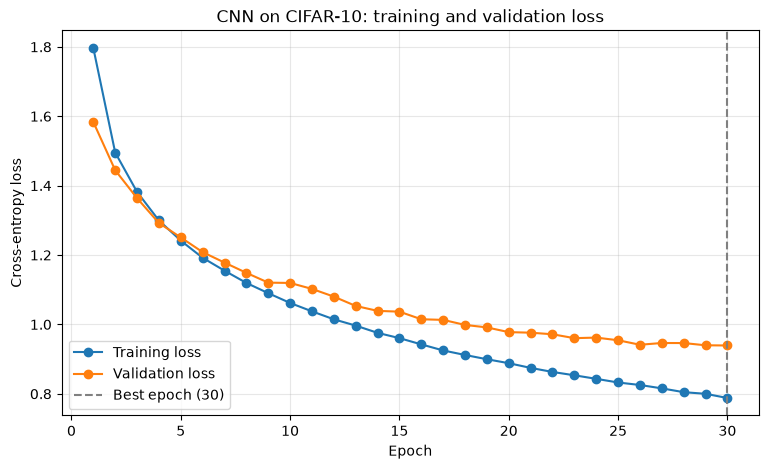

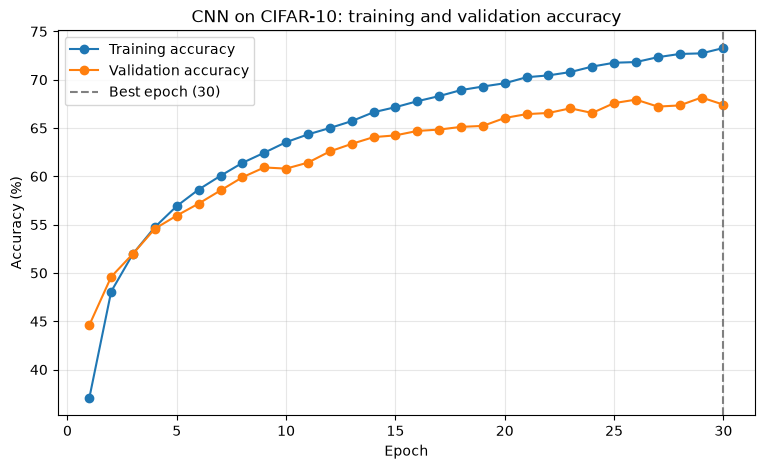

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,epoch_seconds
0,1,1.7968,37.0578,1.5835,44.60,41.3148
1,2,1.4955,48.0778,1.4446,49.60,28.7407
2,3,1.3820,51.9933,1.3640,52.00,25.8906
3,4,1.2996,54.7511,1.2923,54.58,30.7413
4,5,1.2416,56.9244,1.2508,55.94,29.6002
5,6,1.1921,58.6356,1.2084,57.18,27.2720
6,7,1.1549,60.0556,1.1782,58.54,31.4626
7,8,1.1196,61.3933,1.1487,59.90,28.6079
8,9,1.0901,62.4444,1.1204,60.92,27.9723
9,10,1.0618,63.5378,1.1196,60.80,25.6143


In [8]:
figure, axis = plt.subplots(figsize=(9, 5))
axis.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training loss")
axis.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")
axis.axvline(best_epoch, color="grey", linestyle="--", label=f"Best epoch ({best_epoch})")
axis.set_title("CNN on CIFAR-10: training and validation loss")
axis.set_xlabel("Epoch")
axis.set_ylabel("Cross-entropy loss")
axis.grid(alpha=0.3)
axis.legend()
plt.show()

figure, axis = plt.subplots(figsize=(9, 5))
axis.plot(history_df["epoch"], history_df["train_accuracy"], marker="o", label="Training accuracy")
axis.plot(history_df["epoch"], history_df["val_accuracy"], marker="o", label="Validation accuracy")
axis.axvline(best_epoch, color="grey", linestyle="--", label=f"Best epoch ({best_epoch})")
axis.set_title("CNN on CIFAR-10: training and validation accuracy")
axis.set_xlabel("Epoch")
axis.set_ylabel("Accuracy (%)")
axis.grid(alpha=0.3)
axis.legend()
plt.show()

history_df.round(4)


## 8. Final test evaluation

The test loader is created only after training and model selection are complete. The best validation-loss state is loaded, and the untouched test partition is evaluated once.


In [9]:
if best_state is None:
    raise RuntimeError("Training did not produce a best model state.")

model.load_state_dict(best_state)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_settings)

train_loss, train_accuracy, _, _ = evaluate(model, train_loader, criterion, DEVICE)
val_loss, val_accuracy, _, _ = evaluate(model, val_loader, criterion, DEVICE)
test_loss, test_accuracy, test_predictions, test_labels = evaluate(model, test_loader, criterion, DEVICE)

final_results = pd.DataFrame(
    {"loss": [train_loss, val_loss, test_loss], "accuracy (%)": [train_accuracy, val_accuracy, test_accuracy]},
    index=["train", "validation", "test"],
)
print(f"Best epoch: {best_epoch}")
print(final_results.round(4).to_string())


Best epoch: 30
              loss  accuracy (%)
train       0.7717       74.1444
validation  0.9393       67.4200
test        0.9224       68.3300


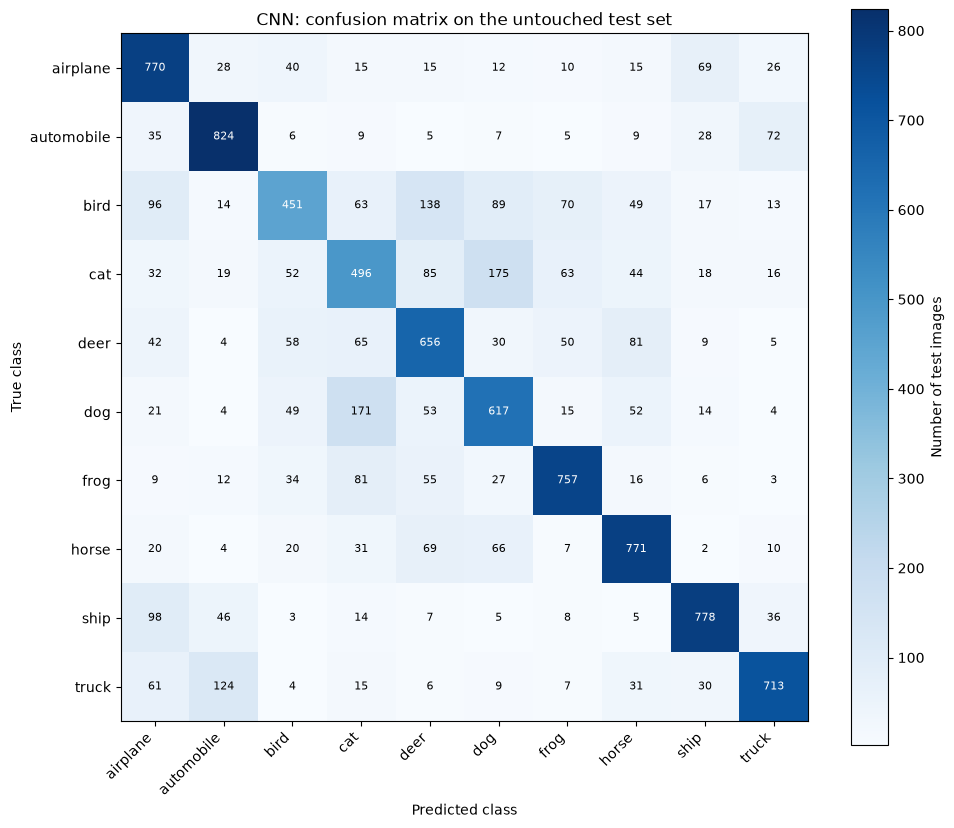

              precision    recall  f1-score   support

    airplane     0.6503    0.7700    0.7051      1000
  automobile     0.7637    0.8240    0.7927      1000
        bird     0.6290    0.4510    0.5253      1000
         cat     0.5167    0.4960    0.5061      1000
        deer     0.6024    0.6560    0.6281      1000
         dog     0.5950    0.6170    0.6058      1000
        frog     0.7631    0.7570    0.7600      1000
       horse     0.7185    0.7710    0.7438      1000
        ship     0.8012    0.7780    0.7894      1000
       truck     0.7940    0.7130    0.7513      1000

    accuracy                         0.6833     10000
   macro avg     0.6834    0.6833    0.6808     10000
weighted avg     0.6834    0.6833    0.6808     10000



In [10]:
test_confusion = confusion_matrix(test_labels, test_predictions)

figure, axis = plt.subplots(figsize=(10, 8.5))
heatmap = axis.imshow(test_confusion, cmap="Blues")
figure.colorbar(heatmap, ax=axis, label="Number of test images")
threshold = test_confusion.max() / 2
for true_index, predicted_index in np.ndindex(test_confusion.shape):
    count = test_confusion[true_index, predicted_index]
    axis.text(predicted_index, true_index, count, ha="center", va="center",
              color="white" if count > threshold else "black", fontsize=8)
axis.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
axis.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
axis.set_xlabel("Predicted class")
axis.set_ylabel("True class")
axis.set_title("CNN: confusion matrix on the untouched test set")
plt.tight_layout()
plt.show()

print(classification_report(test_labels, test_predictions, target_names=CLASS_NAMES, digits=4))


## 9. MLP versus CNN comparison

The table below combines the actual saved Exercise 1 metrics with the actual CNN metrics produced by this run.


In [11]:
comparison = pd.DataFrame(
    {
        "Train loss": [mlp_metrics["train"]["loss"], train_loss],
        "Train accuracy (%)": [mlp_metrics["train"]["accuracy"], train_accuracy],
        "Validation loss": [mlp_metrics["validation"]["loss"], val_loss],
        "Validation accuracy (%)": [mlp_metrics["validation"]["accuracy"], val_accuracy],
        "Test accuracy (%)": [mlp_metrics["test"]["accuracy"], test_accuracy],
        "Trainable parameters": [mlp_metrics["parameter_count"], PARAMETER_COUNT],
    },
    index=["Exercise 1 MLP", "Exercise 2 CNN"],
)
comparison.round(4)


,Train loss,Train accuracy (%),Validation loss,Validation accuracy (%),Test accuracy (%),Trainable parameters
Exercise 1 MLP,0.8078,73.6956,1.3429,54.58,54.06,1707274
Exercise 2 CNN,0.7717,74.1444,0.9393,67.42,68.33,60362


## 10. Discussion and conclusion

The comparison uses the actual Exercise 1 MLP result (54.06% test accuracy, 1,707,274 parameters) and the actual CNN result shown above. Differences should be attributed only after the CNN training cell has completed.

**Why convolution is useful:** Unlike an MLP, which receives flattened pixel values and learns connections across all positions, a convolutional layer applies the same small kernel across the whole image. This weight sharing is efficient and gives the CNN spatial and translation-aware feature detection.

**Feature learning:** Early convolution kernels can learn simple edges and colour contrasts. Deeper features are formed from combinations of earlier features, allowing more complex texture and shape patterns to emerge through training.

**Pooling:** Max pooling reduces spatial size and sensitivity to small translations while retaining strong local responses. Here, two pooling operations reduce the image from 32 x 32 to 8 x 8 before flattening.

**Parameters and architecture:** The CNN uses 60,362 trainable parameters, far fewer than the MLP. This does not guarantee better accuracy: it provides a more suitable structure for local image patterns but still depends on the optimiser, epochs, learning rate, dataset variety and generalisation.

**Limitations:** The architecture has limited depth and does not use augmentation or dropout. It is therefore a simple baseline rather than a maximally tuned CIFAR-10 model. The final test result is valid for comparison only because it was held out until model selection was complete.

The best CNN checkpoint was selected using validation loss, not test accuracy. This is the appropriate model-selection procedure for a controlled experiment.
